<a href="https://colab.research.google.com/github/PavelShershov/Machine_Learning/blob/main/KNN_Shershov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Реализовать класс KNN и проверить его работу на наборах данных MNIST, Fashion-MNIST и CIFAR-10.
2. Нормализовать изображения, определить точность классификации при разных значениях K, время выполнения и показать примеры изображений, на которых алгоритм ошибается.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import gc

from statistics import multimode

import tensorflow as tf
import keras
from keras import datasets

print('TensorFlow:', tf.__version__)
print('Keras:', keras.__version__)


TensorFlow: 2.22.0-rc1
Keras: 3.16.0.dev2026112103


In [ ]:
class KNN(object):

    def __init__(self):
        pass

    def fit(self, X_train, y_train, X_test, y_test):
        self.X_train = X_train
        self.y_train = np.asarray(y_train).reshape(-1)
        self.X_test = X_test
        self.y_test = np.asarray(y_test).reshape(-1)

    def predict_lp(self, max_k=19):
        m_test = self.X_test.shape[0]
        m_train = self.X_train.shape[0]

        max_k = min(max_k, m_train)

        # Для проверки K от 1 до 19 сохраняем только 19 ближайших соседей
        self.indices_predict = np.zeros((m_test, max_k), dtype=int)
        self.labels_predict = np.zeros((m_test, max_k), dtype=self.y_train.dtype)

        for i in range(m_test):
            distances = np.sum(
                np.abs(self.X_train - self.X_test[i, :]),
                axis=1
            )

            self.indices_predict[i] = np.argsort(distances)[:max_k]
            self.labels_predict[i] = self.y_train[self.indices_predict[i]]

            if (i + 1) % 25 == 0 or i + 1 == m_test:
                print(
                    f"Обработано тестовых изображений: {i + 1}/{m_test}",
                    end="\r",
                    flush=True
                )

        print()

    def accuracy(self, k):
        forecast = np.array([
            multimode(row[:k])[0] for row in self.labels_predict
        ])

        score = np.mean(forecast == self.y_test)
        print(f"K = {k}: accuracy = {score:.4f}")

        return forecast, score


In [ ]:
def balanced_subset(X, y, examples_per_class, seed=42):
    y = np.asarray(y).reshape(-1)
    rng = np.random.default_rng(seed)

    selected_indexes = []

    for class_label in np.unique(y):
        class_indexes = np.where(y == class_label)[0]
        selected = rng.choice(
            class_indexes,
            size=examples_per_class,
            replace=False
        )
        selected_indexes.extend(selected)

    selected_indexes = np.asarray(selected_indexes)
    rng.shuffle(selected_indexes)

    return X[selected_indexes], y[selected_indexes]


def show_images(X, y, class_names, gray=True):
    rng = np.random.default_rng(42)
    indexes = rng.permutation(len(X))[:10]

    plt.figure(figsize=(20, 2))

    for count, index in enumerate(indexes, start=1):
        plt.subplot(1, 10, count)
        plt.title(class_names[int(y[index])], fontsize=8)

        if gray:
            plt.imshow(X[index], cmap="gray")
        else:
            plt.imshow(X[index])

        plt.axis("off")

    plt.show()


def show_errors(X_test, y_test, y_predict, class_names, gray=True):
    errors = np.where(y_test != y_predict)[0]

    print("Количество ошибок:", len(errors))

    if len(errors) == 0:
        return

    indexes = errors[:min(10, len(errors))]

    plt.figure(figsize=(16, 3))

    for count, index in enumerate(indexes, start=1):
        plt.subplot(1, len(indexes), count)

        if gray:
            plt.imshow(X_test[index].reshape(28, 28), cmap="gray")
        else:
            plt.imshow(X_test[index].reshape(32, 32, 3))

        plt.title(
            f"Правильно: {class_names[int(y_test[index])]}\n"
            f"Прогноз: {class_names[int(y_predict[index])]}",
            fontsize=8
        )
        plt.axis("off")

    plt.show()


def run_experiment(X_train, y_train, X_test, y_test, class_names, gray=True):
    model = KNN()
    model.fit(X_train, y_train, X_test, y_test)

    start_time = time.time()
    model.predict_lp()
    print("Время выполнения:", round(time.time() - start_time, 2), "сек.")

    scores = {}
    forecasts = {}

    for k in range(1, 20):
        forecast, score = model.accuracy(k)
        scores[k] = score
        forecasts[k] = forecast

    best_k = max(scores, key=scores.get)
    best_predict = forecasts[best_k]

    print("\nЛучшее значение K:", best_k)
    print("Точность:", round(scores[best_k] * 100, 2), "%")
    print("Правильно распознано:", int(np.sum(best_predict == y_test)))

    show_errors(
        X_test,
        y_test,
        best_predict,
        class_names,
        gray=gray
    )

    return best_k, scores[best_k]


MNIST: (60000, 28, 28) (10000, 28, 28)


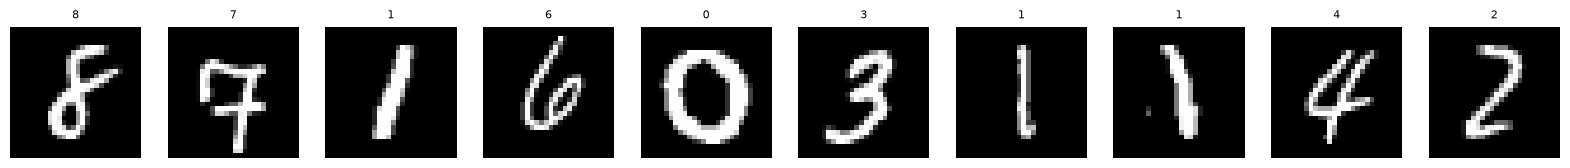

Обработано тестовых изображений: 10000/10000
Время выполнения: 1348.47 сек.
K = 1: accuracy = 0.9631
K = 2: accuracy = 0.9631
K = 3: accuracy = 0.9640
K = 4: accuracy = 0.9656
K = 5: accuracy = 0.9629
K = 6: accuracy = 0.9643
K = 7: accuracy = 0.9618
K = 8: accuracy = 0.9622
K = 9: accuracy = 0.9605
K = 10: accuracy = 0.9615
K = 11: accuracy = 0.9597
K = 12: accuracy = 0.9601
K = 13: accuracy = 0.9592
K = 14: accuracy = 0.9593
K = 15: accuracy = 0.9587
K = 16: accuracy = 0.9587
K = 17: accuracy = 0.9579
K = 18: accuracy = 0.9572
K = 19: accuracy = 0.9573

Лучшее значение K: 4
Точность: 96.56 %
Правильно распознано: 9656
Количество ошибок: 344


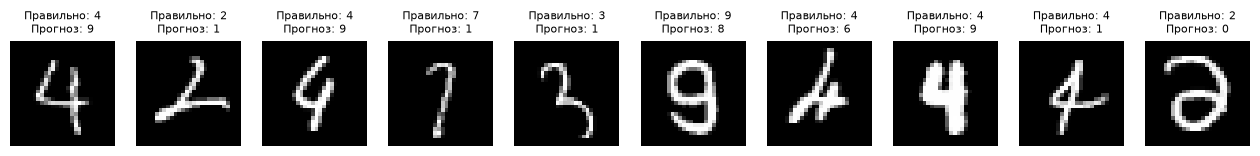

36566

In [ ]:
(X_train, y_train), (X_test, y_test) = datasets.mnist.load_data()

mnist_names = [str(i) for i in range(10)]

print("MNIST:", X_train.shape, X_test.shape)
show_images(X_train, y_train, mnist_names)

X_train = X_train.reshape(X_train.shape[0], -1).astype("float32") / 255
X_test = X_test.reshape(X_test.shape[0], -1).astype("float32") / 255

result_mnist = run_experiment(
    X_train, y_train, X_test, y_test, mnist_names
)

del X_train, y_train, X_test, y_test
gc.collect()


Fashion-MNIST: (60000, 28, 28) (10000, 28, 28)


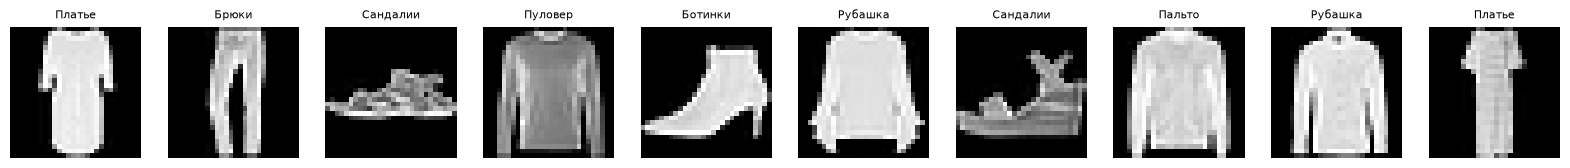

Обработано тестовых изображений: 10000/10000
Время выполнения: 1363.64 сек.
K = 1: accuracy = 0.8526
K = 2: accuracy = 0.8526
K = 3: accuracy = 0.8592
K = 4: accuracy = 0.8612
K = 5: accuracy = 0.8616
K = 6: accuracy = 0.8633
K = 7: accuracy = 0.8609
K = 8: accuracy = 0.8608
K = 9: accuracy = 0.8593
K = 10: accuracy = 0.8594
K = 11: accuracy = 0.8591
K = 12: accuracy = 0.8579
K = 13: accuracy = 0.8566
K = 14: accuracy = 0.8566
K = 15: accuracy = 0.8547
K = 16: accuracy = 0.8543
K = 17: accuracy = 0.8548
K = 18: accuracy = 0.8542
K = 19: accuracy = 0.8533

Лучшее значение K: 6
Точность: 86.33 %
Правильно распознано: 8633
Количество ошибок: 1367


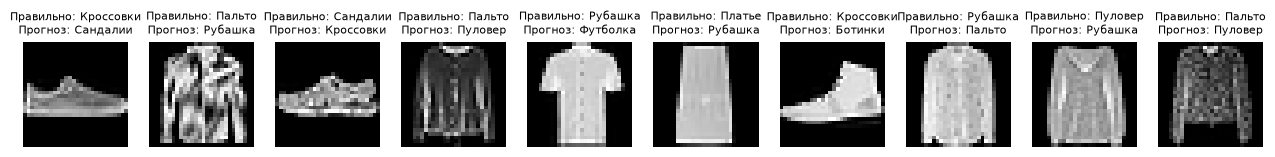

36590

In [ ]:
(X_train, y_train), (X_test, y_test) = datasets.fashion_mnist.load_data()

fashion_names = [
    "Футболка",
    "Брюки",
    "Пуловер",
    "Платье",
    "Пальто",
    "Сандалии",
    "Рубашка",
    "Кроссовки",
    "Сумка",
    "Ботинки"
]

print("Fashion-MNIST:", X_train.shape, X_test.shape)
show_images(X_train, y_train, fashion_names)

X_train = X_train.reshape(X_train.shape[0], -1).astype("float32") / 255
X_test = X_test.reshape(X_test.shape[0], -1).astype("float32") / 255

result_fashion = run_experiment(
    X_train, y_train, X_test, y_test, fashion_names
)

del X_train, y_train, X_test, y_test
gc.collect()


CIFAR-10: (2000, 32, 32, 3) (100, 32, 32, 3)


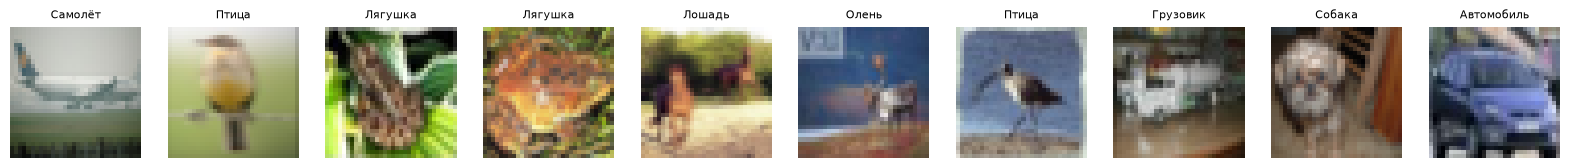

Обработано тестовых изображений: 100/100
Время выполнения: 1.74 сек.
K = 1: accuracy = 0.2200
K = 2: accuracy = 0.2200
K = 3: accuracy = 0.2200
K = 4: accuracy = 0.2500
K = 5: accuracy = 0.2500
K = 6: accuracy = 0.2600
K = 7: accuracy = 0.2800
K = 8: accuracy = 0.2900
K = 9: accuracy = 0.3100
K = 10: accuracy = 0.2400
K = 11: accuracy = 0.2500
K = 12: accuracy = 0.2800
K = 13: accuracy = 0.2900
K = 14: accuracy = 0.2700
K = 15: accuracy = 0.2600
K = 16: accuracy = 0.2200
K = 17: accuracy = 0.2300
K = 18: accuracy = 0.2400
K = 19: accuracy = 0.2200

Лучшее значение K: 9
Точность: 31.0 %
Правильно распознано: 31
Количество ошибок: 69


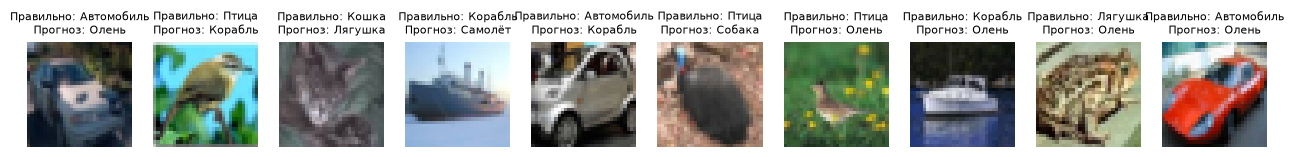

36650

In [ ]:
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)

X_train, y_train = balanced_subset(
    X_train, y_train, examples_per_class=200, seed=46
)
X_test, y_test = balanced_subset(
    X_test, y_test, examples_per_class=10, seed=47
)

cifar_names = [
    "Самолёт",
    "Автомобиль",
    "Птица",
    "Кошка",
    "Олень",
    "Собака",
    "Лягушка",
    "Лошадь",
    "Корабль",
    "Грузовик"
]

print("CIFAR-10:", X_train.shape, X_test.shape)
show_images(X_train, y_train, cifar_names, gray=False)

X_train = X_train.reshape(X_train.shape[0], -1).astype("float32") / 255
X_test = X_test.reshape(X_test.shape[0], -1).astype("float32") / 255

result_cifar = run_experiment(
    X_train, y_train, X_test, y_test, cifar_names, gray=False
)

del X_train, y_train, X_test, y_test
gc.collect()


In [ ]:
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ")

print(
    f"MNIST: K = {result_mnist[0]}, "
    f"accuracy = {result_mnist[1]:.4f}"
)
print(
    f"Fashion-MNIST: K = {result_fashion[0]}, "
    f"accuracy = {result_fashion[1]:.4f}"
)
print(
    f"CIFAR-10: K = {result_cifar[0]}, "
    f"accuracy = {result_cifar[1]:.4f}"
)


ИТОГОВЫЕ РЕЗУЛЬТАТЫ
MNIST: K = 4, accuracy = 0.9656
Fashion-MNIST: K = 6, accuracy = 0.8633
CIFAR-10: K = 9, accuracy = 0.3100
